# Plastic pyrolysis yield prediction

**Question:** Can a model predict pyrolysis product yields (liquid / gas / solid)
from feedstock and operating conditions across different plastics, and tell us
which conditions matter most?

Plastic waste cracks thermally into a liquid (oil/wax), a non-condensable gas,
and a solid char. The split depends on plastic type, temperature, residence
time, heating rate, catalyst, and reactor. We learn that mapping from published
experiments.

Approach: three regressors (one per fraction), compare RandomForest / XGBoost /
LightGBM with k-fold cross-validation (the dataset is small), explain with SHAP,
and normalize the three predictions to sum to 100 %.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import shap
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("data") if Path("data").exists() else Path("../data")
MODEL_DIR = Path("models") if Path("models").exists() else Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
plt.rcParams["figure.figsize"] = (7, 4)

## 2. Load data

Uses `data/dataset_template.csv` once it has real rows. Until then it falls back
to generated **synthetic** data and warns loudly. Replace the synthetic data
with real experiments before drawing any conclusions.

In [2]:
def generate_synthetic(n=180, seed=RANDOM_STATE):
    """Fake but physically-plausible pyrolysis data, only to exercise the pipeline.
    Relationships are hand-coded so SHAP shows sensible drivers (temperature,
    plastic type, catalyst). This is NOT real experimental data."""
    rng = np.random.default_rng(seed)
    plastics = ["PE", "PP", "PS", "PET", "PVC", "mixed"]
    reactors = ["fixed_bed", "fluidized_bed", "batch", "semi_batch", "screw"]
    catalysts = ["none", "zeolite", "HZSM-5", "FCC"]

    base_liquid = {"PE": 72, "PP": 76, "PS": 82, "PET": 40, "PVC": 30, "mixed": 58}
    base_gas    = {"PE": 18, "PP": 16, "PS": 12, "PET": 35, "PVC": 40, "mixed": 26}
    base_solid  = {"PE": 8,  "PP": 8,  "PS": 6,  "PET": 25, "PVC": 30, "mixed": 16}

    pt = rng.choice(plastics, n)
    temp = rng.uniform(400, 700, n)
    res = rng.uniform(5, 90, n)
    rate = rng.uniform(5, 50, n)
    cat = rng.choice(catalysts, n, p=[0.40, 0.25, 0.20, 0.15])
    cat_ratio = np.where(cat == "none", 0.0, rng.uniform(0.05, 0.30, n)).round(3)
    reactor = rng.choice(reactors, n)
    psize = rng.uniform(0.2, 5.0, n).round(2)
    feed = rng.uniform(5, 500, n).round(1)

    bl = np.array([base_liquid[p] for p in pt], float)
    bg = np.array([base_gas[p] for p in pt], float)
    bs = np.array([base_solid[p] for p in pt], float)

    noise = lambda: rng.normal(0, 2, n)
    # temperature: liquid peaks ~500C, gas rises with temp, char falls with temp
    liq = bl - 0.0018 * (temp - 500) ** 2 - 20 * cat_ratio - 0.12 * (res - 30) + 0.10 * (rate - 25) + noise()
    gas = bg + 0.05 * (temp - 500) + 25 * cat_ratio + 0.15 * (res - 30) + noise()
    sol = bs - 0.02 * (temp - 500) - 3 * cat_ratio - 0.05 * (rate - 25) + noise()

    scores = np.clip(np.vstack([liq, gas, sol]), 1.0, None)
    scores = 100 * scores / scores.sum(axis=0)

    return pd.DataFrame({
        "plastic_type": pt, "temperature_C": temp.round(0), "residence_time_min": res.round(1),
        "heating_rate_C_min": rate.round(1), "catalyst": cat, "catalyst_ratio": cat_ratio,
        "reactor_type": reactor, "particle_size_mm": psize, "feed_mass_g": feed,
        "liquid_yield_pct": scores[0].round(1), "gas_yield_pct": scores[1].round(1),
        "solid_yield_pct": scores[2].round(1), "source": "SYNTHETIC",
        "notes": "generated demo data - not real",
    })


template = DATA_DIR / "dataset_template.csv"
synth = DATA_DIR / "example_synthetic.csv"

real = pd.read_csv(template)
if len(real) >= 20:
    df, is_synthetic = real, False
    print(f"Using REAL dataset: {len(df)} rows from {template.name}")
else:
    if not synth.exists():
        generate_synthetic().to_csv(synth, index=False)
    df, is_synthetic = pd.read_csv(synth), True
    print("=" * 72)
    print("  SYNTHETIC DEMO DATA - NOT REAL. Do not report these results.")
    print("  Add real rows to data/dataset_template.csv, then rerun.")
    print("=" * 72)

df.head()

  SYNTHETIC DEMO DATA - NOT REAL. Do not report these results.
  Add real rows to data/dataset_template.csv, then rerun.


,plastic_type,temperature_C,residence_time_min,heating_rate_C_min,catalyst,catalyst_ratio,reactor_type,particle_size_mm,feed_mass_g,liquid_yield_pct,gas_yield_pct,solid_yield_pct,source,notes
0,PE,446.0,9.7,6.9,FCC,0.051,semi_batch,1.37,26.9,74.6,17.3,8.1,SYNTHETIC,generated demo data - not real
1,PVC,609.0,19.8,44.8,HZSM-5,0.054,semi_batch,4.58,203.6,12.6,56.1,31.3,SYNTHETIC,generated demo data - not real
2,PET,534.0,9.5,36.9,none,0.000,fixed_bed,4.63,165.3,41.9,35.3,22.8,SYNTHETIC,generated demo data - not real
3,PS,514.0,55.2,12.8,none,0.000,semi_batch,4.25,474.6,79.8,15.8,4.4,SYNTHETIC,generated demo data - not real
4,PS,490.0,62.9,9.1,none,0.000,semi_batch,4.90,290.5,78.1,16.8,5.1,SYNTHETIC,generated demo data - not real


## 3. Explore

In [3]:
TARGETS = ["liquid_yield_pct", "gas_yield_pct", "solid_yield_pct"]
print("shape:", df.shape)
print(df[TARGETS].describe().round(1))

ysum = df[TARGETS].sum(axis=1)
print(f"\nyield sum -> mean {ysum.mean():.1f}, min {ysum.min():.1f}, max {ysum.max():.1f}")

shape: (180, 14)
       liquid_yield_pct  gas_yield_pct  solid_yield_pct
count             180.0          180.0            180.0
mean               43.0           39.6             17.3
std                26.1           17.0             11.6
min                 1.2            9.0              1.0
25%                21.9           25.4              6.7
50%                45.3           38.0             14.2
75%                66.4           50.8             28.5
max                83.9           90.4             39.4

yield sum -> mean 100.0, min 99.9, max 100.1


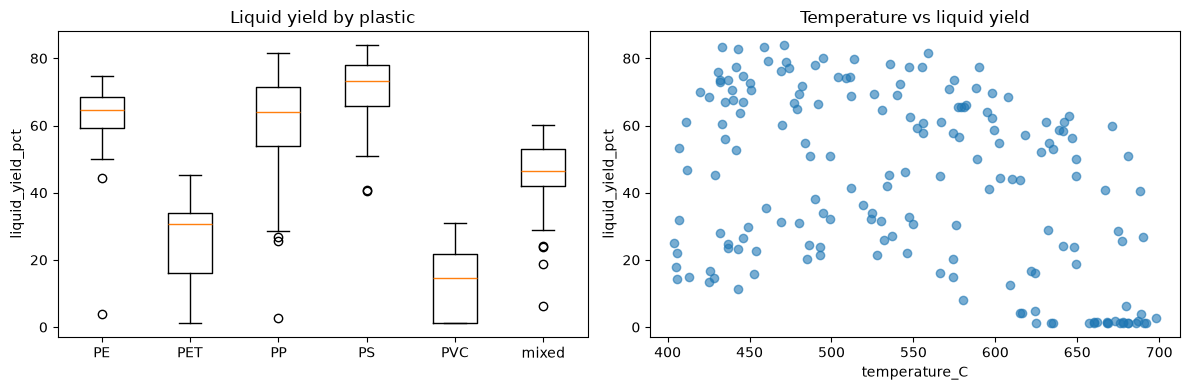

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

order = sorted(df["plastic_type"].unique())
axes[0].boxplot([df.loc[df.plastic_type == p, "liquid_yield_pct"] for p in order], tick_labels=order)
axes[0].set_title("Liquid yield by plastic"); axes[0].set_ylabel("liquid_yield_pct")

axes[1].scatter(df["temperature_C"], df["liquid_yield_pct"], alpha=0.6)
axes[1].set_xlabel("temperature_C"); axes[1].set_ylabel("liquid_yield_pct")
axes[1].set_title("Temperature vs liquid yield")
plt.tight_layout(); plt.show()

## 4. Features and preprocessing

In [5]:
CAT_FEATURES = ["plastic_type", "catalyst", "reactor_type"]
NUM_FEATURES = ["temperature_C", "residence_time_min", "heating_rate_C_min",
                "catalyst_ratio", "particle_size_mm", "feed_mass_g"]
FEATURES = CAT_FEATURES + NUM_FEATURES

X = df[FEATURES].copy()
y = df[TARGETS].copy()

def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
        ("num", "passthrough", NUM_FEATURES),
    ])

## 5. Model comparison (cross-validated)

Small data, so we score with 5-fold cross-validation instead of a single split.
RandomForest, XGBoost, and LightGBM, each fraction separately.

In [6]:
def make_models():
    return {
        "RandomForest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                subsample=0.9, colsample_bytree=0.9,
                                random_state=RANDOM_STATE, verbosity=0),
        "LightGBM": LGBMRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                  num_leaves=15, min_child_samples=5,
                                  random_state=RANDOM_STATE, verbose=-1),
    }

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for target in TARGETS:
    for name, model in make_models().items():
        pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
        pred = cross_val_predict(pipe, X, y[target], cv=cv)
        rows.append({
            "target": target, "model": name,
            "R2": r2_score(y[target], pred),
            "MAE": mean_absolute_error(y[target], pred),
            "RMSE": mean_squared_error(y[target], pred) ** 0.5,
        })
results = pd.DataFrame(rows)
results.round(3)

,target,model,R2,MAE,RMSE
0,liquid_yield_pct,RandomForest,0.934,4.766,6.705
1,liquid_yield_pct,XGBoost,0.945,4.465,6.130
2,liquid_yield_pct,LightGBM,0.944,4.307,6.159
3,gas_yield_pct,RandomForest,0.866,4.611,6.221
4,gas_yield_pct,XGBoost,0.882,4.237,5.831
5,gas_yield_pct,LightGBM,0.896,3.876,5.491
6,solid_yield_pct,RandomForest,0.933,2.265,2.988
7,solid_yield_pct,XGBoost,0.932,2.319,3.025
8,solid_yield_pct,LightGBM,0.929,2.365,3.073


In [7]:
print("Cross-validated R2 by model:")
print(results.pivot(index="model", columns="target", values="R2").round(3))

best_per_target = results.loc[results.groupby("target")["R2"].idxmax()].set_index("target")["model"]
print("\nBest model per fraction:")
print(best_per_target.to_string())

Cross-validated R2 by model:
target        gas_yield_pct  liquid_yield_pct  solid_yield_pct
model                                                         
LightGBM              0.896             0.944            0.929
RandomForest          0.866             0.934            0.933
XGBoost               0.882             0.945            0.932

Best model per fraction:
target
gas_yield_pct           LightGBM
liquid_yield_pct         XGBoost
solid_yield_pct     RandomForest


## 6. Fit final models and check predicted vs actual

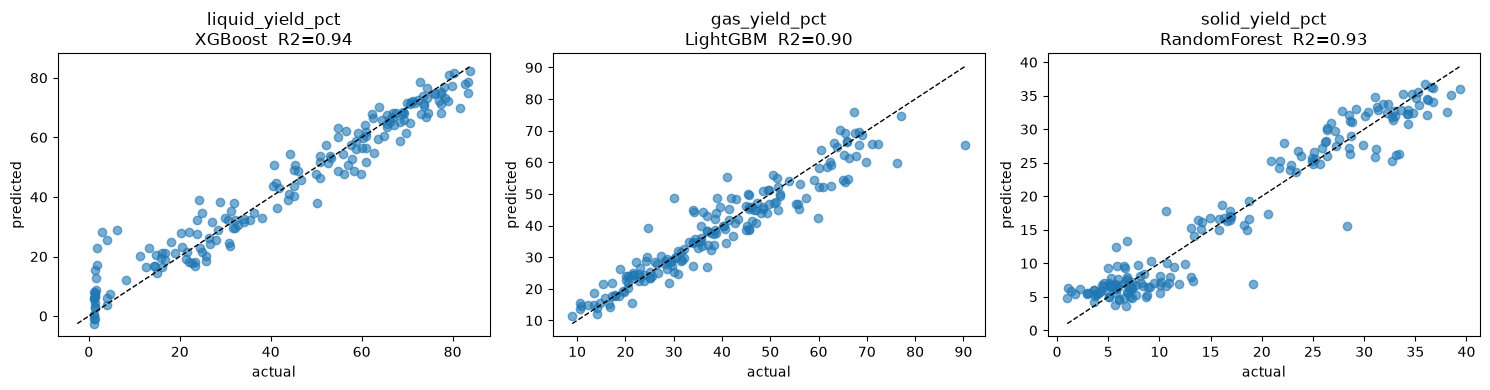

In [8]:
final_models = {}
oof_pred = {}                       # out-of-fold predictions, reused for conformal intervals
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, target in zip(axes, TARGETS):
    best = best_per_target[target]
    pipe = Pipeline([("prep", make_preprocessor()), ("model", make_models()[best])])
    pred = cross_val_predict(pipe, X, y[target], cv=cv)   # honest, out-of-fold
    oof_pred[target] = pred
    ax.scatter(y[target], pred, alpha=0.6)
    lims = [min(y[target].min(), pred.min()), max(y[target].max(), pred.max())]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlabel("actual"); ax.set_ylabel("predicted")
    ax.set_title(f"{target}\n{best}  R2={r2_score(y[target], pred):.2f}")
    pipe.fit(X, y[target])          # refit on all data for saving/use
    final_models[target] = pipe
plt.tight_layout(); plt.show()

## 7. Which conditions matter? (SHAP)

SHAP on the liquid-yield model. Positive values push the predicted yield up,
negative down. In the literature temperature, plastic type, and catalyst
dominate. (On synthetic data this just confirms the pipeline works.)

/var/folders/m5/rnwzbv2s35x737bggbrtnksc0000gp/T/ipykernel_6915/49677224.py:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_trans, feature_names=feat_names, show=True)


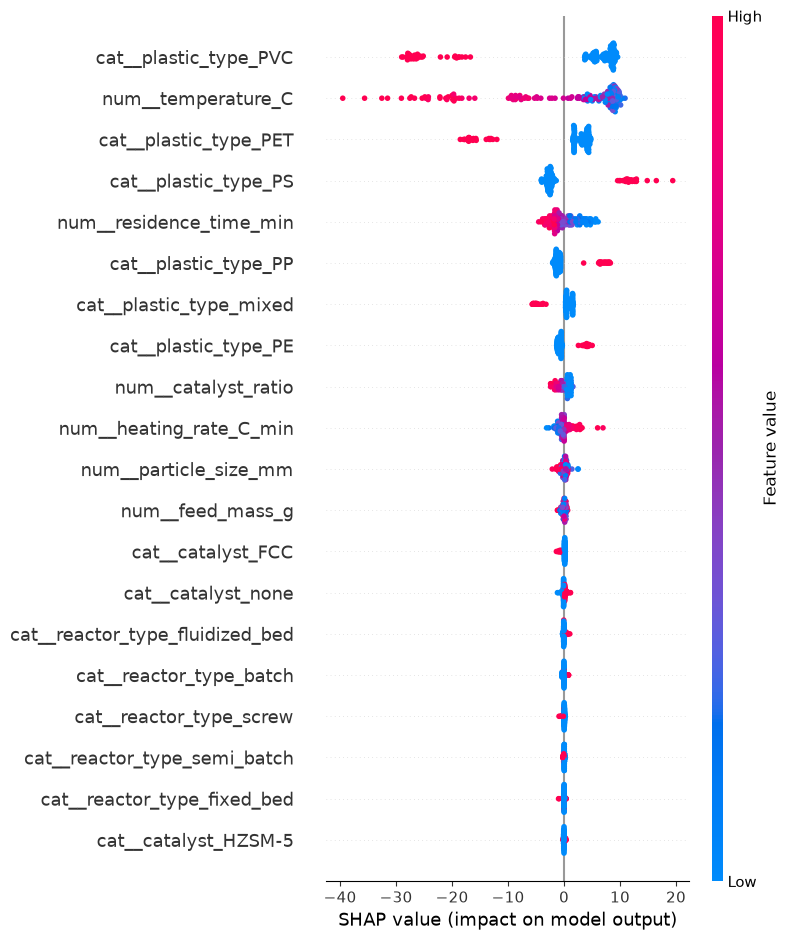

In [9]:
target = "liquid_yield_pct"
prep = final_models[target].named_steps["prep"]
model = final_models[target].named_steps["model"]

X_trans = prep.transform(X)
feat_names = prep.get_feature_names_out()

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_trans)
shap.summary_plot(shap_values, X_trans, feature_names=feat_names, show=True)

## 8. Trust part 1: how sure is the model? (conformal intervals)

A point prediction with no error bar is dishonest on data this small. We reuse
the out-of-fold predictions from section 6: the absolute residuals give a
distribution-free ~90% interval (split-conformal style). Then we check the
interval really covers ~90% of held-out points.

In [10]:
ALPHA = 0.10   # target 90% intervals
qhat = {}
print("Conformal half-width (wt%) and empirical coverage per fraction:")
for target in TARGETS:
    resid = np.abs(y[target].values - oof_pred[target])
    qhat[target] = float(np.quantile(resid, 1 - ALPHA))
    covered = float(np.mean(resid <= qhat[target]))
    print(f"  {target:18s}  +/- {qhat[target]:5.1f}   coverage {covered:.2f}")

Conformal half-width (wt%) and empirical coverage per fraction:
  liquid_yield_pct    +/-   9.4   coverage 0.90
  gas_yield_pct       +/-   8.7   coverage 0.90
  solid_yield_pct     +/-   4.4   coverage 0.90


## 9. Trust part 2: is this in-domain or extrapolating?

The model is only trustworthy near conditions it has actually seen. We measure
distance to the training data in the standardized, encoded feature space and flag
any query whose distance is larger than what we see inside the training set.

In [11]:
ad_prep = Pipeline([("prep", make_preprocessor()), ("scale", StandardScaler())])
X_ad = ad_prep.fit_transform(X)

ad_nn = NearestNeighbors(n_neighbors=6).fit(X_ad)          # self + 5 neighbours
train_dist = ad_nn.kneighbors(X_ad)[0][:, 1:].mean(axis=1)  # drop self-distance
AD_THRESHOLD = float(np.quantile(train_dist, 0.95))

def domain_score(conditions: dict):
    row = pd.DataFrame([conditions])[FEATURES]
    d = ad_nn.kneighbors(ad_prep.transform(row))[0][0][:5].mean()
    return float(d), bool(d <= AD_THRESHOLD)

print(f"in-domain threshold (95th pct of training distances): {AD_THRESHOLD:.2f}")

in-domain threshold (95th pct of training distances): 4.68


## 10. Trust-aware prediction

`predict_yields` now returns each fraction's normalized point estimate plus a
`+/-` band and an overall in-domain flag. (Caveat: the band is the raw per-model
conformal width, reported before the sum-to-100 normalization.)

In [12]:
def predict_yields(conditions: dict) -> dict:
    """Normalized point yields + conformal band + in-domain flag."""
    row = pd.DataFrame([conditions])[FEATURES]
    raw = {t: max(float(final_models[t].predict(row)[0]), 0.0) for t in TARGETS}
    total = sum(raw.values()) or 1.0
    score, in_dom = domain_score(conditions)
    out = {"in_domain": in_dom, "ad_score": round(score, 2)}
    for t in TARGETS:
        out[t] = {"yield_pct": round(100 * raw[t] / total, 1),
                  "band_wpct": round(qhat[t], 1)}
    return out


good = {"plastic_type": "PP", "temperature_C": 500, "residence_time_min": 30,
        "heating_rate_C_min": 20, "catalyst": "none", "catalyst_ratio": 0.0,
        "reactor_type": "fixed_bed", "particle_size_mm": 2.0, "feed_mass_g": 100}
silly = {**good, "temperature_C": 1000}    # far outside the data

import json
print("in-domain query:       ", json.dumps(predict_yields(good)))
print("out-of-domain (1000 C):", json.dumps(predict_yields(silly)))

in-domain query:        {"in_domain": true, "ad_score": 3.05, "liquid_yield_pct": {"yield_pct": 77.1, "band_wpct": 9.4}, "gas_yield_pct": {"yield_pct": 16.1, "band_wpct": 8.7}, "solid_yield_pct": {"yield_pct": 6.7, "band_wpct": 4.4}}
out-of-domain (1000 C): {"in_domain": false, "ad_score": 5.49, "liquid_yield_pct": {"yield_pct": 16.3, "band_wpct": 9.4}, "gas_yield_pct": {"yield_pct": 73.3, "band_wpct": 8.7}, "solid_yield_pct": {"yield_pct": 10.4, "band_wpct": 4.4}}


## 11. Condition recommender (inverse optimization)

The differentiator. Instead of "conditions -> yield", ask "what conditions give
the most of product X for this plastic?". We random-search conditions within the
range studied for that plastic, keep only in-domain candidates (the trust guard),
and return the best. Not a paper-grade optimizer, just the fast, honest version.

In [13]:
OBJECTIVES = {"max_liquid": ("liquid_yield_pct", 1), "max_gas": ("gas_yield_pct", 1),
              "max_solid": ("solid_yield_pct", 1), "min_solid": ("solid_yield_pct", -1)}

def recommend_conditions(plastic_type, objective="max_liquid", fixed=None,
                         n_candidates=20000, seed=RANDOM_STATE):
    """Search in-domain conditions for the best of a target product, one plastic."""
    rng = np.random.default_rng(seed)
    fixed = fixed or {}
    sub = df[df["plastic_type"] == plastic_type]
    if len(sub) < 10:                       # too few rows: use the whole set's ranges
        sub = df
    cand = {"plastic_type": np.array([plastic_type] * n_candidates)}
    for col in NUM_FEATURES:
        cand[col] = rng.uniform(sub[col].min(), sub[col].max(), n_candidates)
    for col in ["catalyst", "reactor_type"]:
        cand[col] = rng.choice(sorted(sub[col].dropna().unique()), n_candidates)
    for col, val in fixed.items():
        cand[col] = np.array([val] * n_candidates)
    C = pd.DataFrame(cand)[FEATURES]

    raw = np.vstack([np.clip(final_models[t].predict(C), 0, None) for t in TARGETS]).T
    norm = 100 * raw / raw.sum(axis=1, keepdims=True)
    col, sign = OBJECTIVES[objective]
    score = sign * norm[:, TARGETS.index(col)]

    d = ad_nn.kneighbors(ad_prep.transform(C))[0][:, :5].mean(axis=1)   # in-domain only
    if not (d <= AD_THRESHOLD).any():
        return {"plastic_type": plastic_type, "warning": "no in-domain candidate found"}
    score = np.where(d <= AD_THRESHOLD, score, -np.inf)
    best = int(np.argmax(score))
    rec = {k: (round(float(cand[k][best]), 1) if k in NUM_FEATURES else str(cand[k][best]))
           for k in FEATURES}
    return {"plastic_type": plastic_type, "objective": objective,
            "recommended_conditions": rec, "predicted": predict_yields(rec)}


import json
print(json.dumps(recommend_conditions("PP", "max_liquid"), indent=2))
print(json.dumps(recommend_conditions("PET", "max_gas"), indent=2))

{
  "plastic_type": "PP",
  "objective": "max_liquid",
  "recommended_conditions": {
    "plastic_type": "PP",
    "catalyst": "zeolite",
    "reactor_type": "fixed_bed",
    "temperature_C": 497.5,
    "residence_time_min": 13.1,
    "heating_rate_C_min": 43.0,
    "catalyst_ratio": 0.0,
    "particle_size_mm": 0.9,
    "feed_mass_g": 370.0
  },
  "predicted": {
    "in_domain": true,
    "ad_score": 4.28,
    "liquid_yield_pct": {
      "yield_pct": 81.6,
      "band_wpct": 9.4
    },
    "gas_yield_pct": {
      "yield_pct": 13.1,
      "band_wpct": 8.7
    },
    "solid_yield_pct": {
      "yield_pct": 5.3,
      "band_wpct": 4.4
    }
  }
}


{
  "plastic_type": "PET",
  "objective": "max_gas",
  "recommended_conditions": {
    "plastic_type": "PET",
    "catalyst": "FCC",
    "reactor_type": "semi_batch",
    "temperature_C": 684.3,
    "residence_time_min": 77.1,
    "heating_rate_C_min": 36.4,
    "catalyst_ratio": 0.1,
    "particle_size_mm": 2.0,
    "feed_mass_g": 105.4
  },
  "predicted": {
    "in_domain": true,
    "ad_score": 4.3,
    "liquid_yield_pct": {
      "yield_pct": 0.0,
      "band_wpct": 9.4
    },
    "gas_yield_pct": {
      "yield_pct": 74.7,
      "band_wpct": 8.7
    },
    "solid_yield_pct": {
      "yield_pct": 25.3,
      "band_wpct": 4.4
    }
  }
}


## 12. Save models + trust artifacts

In [14]:
artifact = {
    "models": final_models, "features": FEATURES, "targets": TARGETS,
    "num_features": NUM_FEATURES, "cat_features": CAT_FEATURES,
    "best_per_target": best_per_target.to_dict(),
    "qhat": qhat, "ad_prep": ad_prep, "ad_nn": ad_nn, "ad_threshold": AD_THRESHOLD,
    "trained_on": "SYNTHETIC" if is_synthetic else "real",
}
out = MODEL_DIR / "pyrolysis_models.joblib"
joblib.dump(artifact, out)
print("saved:", out.resolve())

saved: /Users/Dhanis/plastic-pyrolysis-ml/models/pyrolysis_models.joblib


## 13. Limitations and next steps

- **Synthetic data.** Everything above runs on generated numbers. The very next
  step is real rows in `data/dataset_template.csv`; the notebook reruns unchanged.
- **Small data.** Literature datasets are ~150-325 rows. Report cross-validated
  scores (as here), never a single lucky split, and don't over-tune.
- **Conformal caveat.** The `+/-` band is the raw per-fraction width, taken before
  the sum-to-100 normalization, so treat it as an honest guide, not a guarantee.
- **Applicability domain** is a nearest-neighbour distance heuristic, not a proof.
  It catches obvious extrapolation (1000 C), not subtle gaps in the data.
- **Recommender** is random search over the model. Good enough and fast; Bayesian
  optimization or a genetic algorithm would refine it later.
- **Catalyst detail.** `catalyst` + `catalyst_ratio` is coarse. Real catalytic
  behaviour depends on acidity, surface area, etc. Add columns if the data supports it.
- **Later:** a Streamlit demo (slide the conditions, watch yields + recommendation
  update) and a short writeup framing this as research.